<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Стат. свойства в линейных моделях, часть 2</span></h2>

In [1]:
from typing import Iterable, Tuple, Union
import numpy as np
import pandas as pd
import scipy.stats as sps
from tqdm.notebook import tqdm
import warnings
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf
import statsmodels.stats.api as sms
from statsmodels.compat import lzip
import statsmodels.datasets as smd
import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLMResultsWrapper
from ipywidgets import interact, FloatSlider
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

# импорты для датасета про рак
import ssl
import certifi
from statsmodels.datasets import get_rdataset

warnings.filterwarnings("ignore")
sns.set(style="darkgrid", font_scale=1.3, palette="Set2")

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Статистические свойства линейной регрессии</span>


Загрузим датасет 2024 года с данными по стоимости квартир в Москве (<a href="https://www.kaggle.com/datasets/ivan314sh/prices-of-moscow-apartments">источник</a>).

В датасете представлены данные о цене москвоской квартиры и различных характеристиках квартиры. Наша задача &mdash; предсказать цену квартиры по ее описанию.

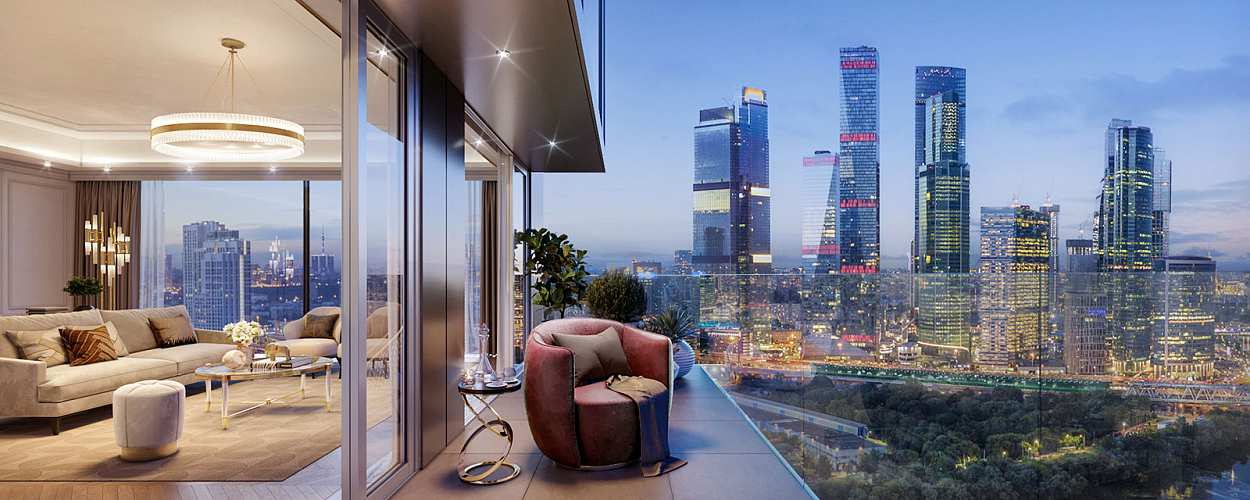

**Описание колонок**

1. **price** — цена объекта недвижимости в рублях (RUB).  
2. **min_to_metro** — примерное время (в минутах) до ближайшего метро.  
3. **region_of_moscow** — административный округ Москвы, в котором находится объект.
4. **total_area** — общая площадь объекта в квадратных метрах.  
5. **living_area** — жилая площадь объекта в квадратных метрах (помещения, предназначенные для проживания).  
6. **floor** — этаж, на котором расположен объект.  
7. **number_of_floors** — общее количество этажей в здании.  
8. **construction_year** — год постройки здания.  
9. **is_new** — бинарный признак (1/0 или да/нет), указывающий, является ли объект новостройкой.  
10. **is_apartments** — бинарный признак (1/0 или да/нет), указывающий, классифицируется ли объект как апартаменты.  
    - Значение **0** — можно официально зарегистрироваться по месту жительства.  
    - Значение **1** — регистрация невозможна (например, апартаменты без инфраструктуры).  
11. **ceiling_height** — высота потолков в метрах.  
12. **number_of_rooms** — количество комнат (включая спальни, гостиную и т.д.).  
13. **link** — URL-ссылка на страницу объекта с подробной информацией.


In [2]:
flats = pd.read_csv("moscow_flats_dataset_eng.csv")
flats = flats[flats.total_area < 300]  # отфильтруем слишком большие квартиры, так как их мало
flats["price"] = flats["price"] / 1000000  # будем измерять цены в миллионах
flats.head()

,price,min_to_metro,region_of_moscow,total_area,living_area,floor,number_of_floors,construction_year,is_new,is_apartments,ceiling_height,number_of_rooms,link
0,31.633073,24.0,SAR,64.2,32.4,11.0,16.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/293204033/
1,29.293000,9.0,NEAR,78.1,NaN,9.0,27.0,2022.0,1.0,0.0,NaN,2.0,https://www.cian.ru/sale/flat/294033524/
2,30.349669,5.0,SAR,72.4,33.6,3.0,24.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/300712697/
3,31.845511,19.0,SAR,69.2,NaN,2.0,12.0,2024.0,1.0,0.0,2.97,2.0,https://www.cian.ru/sale/flat/300228448/
4,38.810000,27.0,WAR,66.9,24.8,9.0,14.0,2023.0,1.0,0.0,3.00,2.0,https://www.cian.ru/sale/flat/299262105/


In [3]:
flats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6930 entries, 0 to 6982
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              6930 non-null   float64
 1   min_to_metro       6816 non-null   float64
 2   region_of_moscow   6862 non-null   object 
 3   total_area         6930 non-null   float64
 4   living_area        4498 non-null   float64
 5   floor              6930 non-null   float64
 6   number_of_floors   6930 non-null   float64
 7   construction_year  5739 non-null   float64
 8   is_new             6919 non-null   float64
 9   is_apartments      6919 non-null   float64
 10  ceiling_height     5038 non-null   float64
 11  number_of_rooms    6930 non-null   float64
 12  link               6930 non-null   object 
dtypes: float64(11), object(2)
memory usage: 758.0+ KB


Посмотрим для начала на зависимость цены квартиры от общей площади и попробуем предсказать цену только по ней.

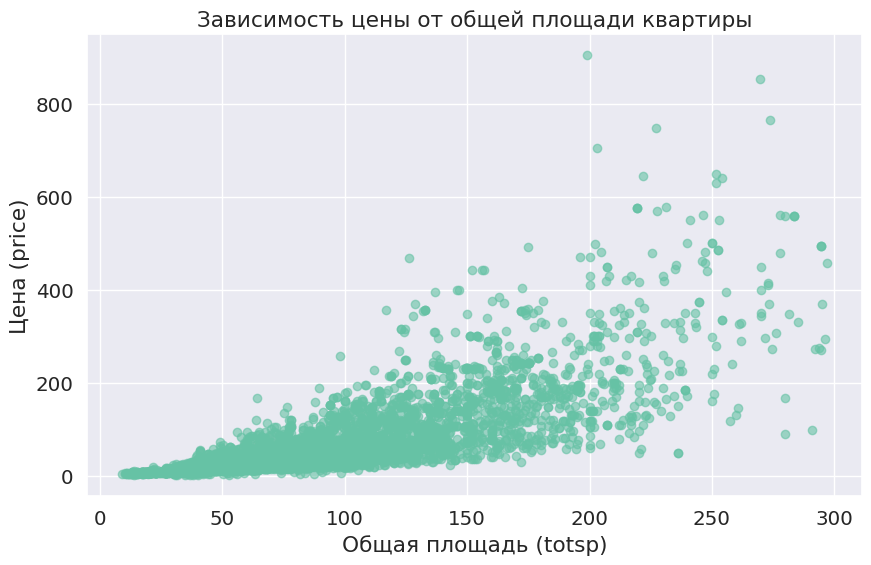

In [4]:
plt.figure(figsize=(10, 6))
plt.scatter(flats["total_area"], flats["price"], alpha=0.6)
plt.xlabel("Общая площадь (totsp)")
plt.ylabel("Цена (price)")
plt.title("Зависимость цены от общей площади квартиры")
plt.grid(True)

plt.show()

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.1</span> <span style="color:inherit;">Обучение простой линейной модели</span>




Сначала обучим линейную регрессию, для этого воспользуемся реализацией `statsmodels.regression.linear_model.OLS`.

> Модель можно задавать двумя способами.
>
> 1. **Матричный подход** (похожий на `sklearn`)
>
>     Как обычно передаем таргет и матрицу признаков. Обратите внимание, что в отличии от `sklearn`, здесь порядок аргументов обратный: **сначала `y` (таргет), потом `X` (признаки)**.<br/><br/>
>
>
> 2. **Подход с использованием формул**
>
>     Этот метод позволяет описать модель на специальном языке формул, что часто бывает нагляднее. Общая структура такой формулы:
>
>     `target ~ features_1 + features_2 + ... + features_d`
>
>     Эта формула в математическом виде представима как
>     $$y(x) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_d x_d$$
>
>     Общие правила определения формулы:
>     * Символ `~` (тильда) является центральным элементом. Его можно прочитать как «объясняется через» или «зависит от». Слева указывается таргет, справа — признаки.  
>     * Справа от тильды перечисляются признаки (столбцы `DataFrame`), которые должны войти в модель в качестве признаков. Их имена записываются через знак `+`.
>     * Константа обычно добавляется в модель автоматически. Если же необходимо явно исключить её, это можно сделать, добавив в конец формулы `-1` или `+0`.
>     * Категориальные признаки можно передать как `C(category_feature)`, они будут преобразованы с помощью one-hot encoding.
>     * Конструкция `feature_1:feature_2` позволяет задать новый признак, равный произведению двух исходных. Это позволяет модели учитывать эффект взаимодействия двух признаков.
>     * Конструкция `feature_1*feature_2` автоматически включает все индивидуальные эффекты и все возможные взаимодействия между указанными признаками. Он эквивалентен конструкции `feature_1 + feature_2 + feature_1:feature_2`
>     * Арифметические выражения в формулу можно включать в с помощью `I(expression)`, например `I(x**2)`.
    

Мы уже поговорили об **устойчивых к гетероскедастичности оценках дисперсий** более подробно в предыдущем ноутбуке а приложении к __предиктивным__ интервалам, но они также влияют на интервалы для оценок коэффициентов. Их правильная инициализация в модели позволяет совершать меньше ошибок в суждении о __значимости__ коэффициентов линейной регрессии. При их использовании доверительные интервалы оценок будут __шире__.

В дальнейшем будем использовать `cov_type="HC3"`.  
Обрати внимание: устойчивые оценки $\widehat{\mathsf{D}}(\widehat{\theta})$ изменяют дисперсии и ковариации коэффициентов, но **не изменяют сами оценки коэффициентов** $\widehat{\theta}$.

In [5]:
linear = smf.ols("price ~ total_area", flats)
lm_results = linear.fit(cov_type="HC3")

Метод `fit` возвращает объект типа `statsmodels.regression.linear_model.RegressionResults`, который содержит всю информацию о модели. В нём можно найти:

* **Общая информация о модели**: параметры обучения, число наблюдений, R², проверка значимости модели в целом, логарифм функции правдоподобия, информационные критерии (AIC, BIC).  
* **Информация о коэффициентах**: оценки коэффициентов, стандартные ошибки, t-статистика, p-value, доверительные интервалы.  
* **Анализ остатков**: проверка несмещённости, нормальности, гомоскедастичности.

Сначала посмотрим на **результат модели в целом**, а затем разберём каждый блок по отдельности.


In [6]:
print(lm_results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     2275.
Date:                Thu, 23 Oct 2025   Prob (F-statistic):               0.00
Time:                        17:03:03   Log-Likelihood:                -36590.
No. Observations:                6930   AIC:                         7.318e+04
Df Residuals:                    6928   BIC:                         7.320e+04
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -45.2832      1.727    -26.216      0.0

In [7]:
lm_results.summary2().tables[0]

,0,1,2,3
0,Model:,OLS,Adj. R-squared:,0.616
1,Dependent Variable:,price,AIC:,73184.3830
2,Date:,2025-10-23 17:03,BIC:,73198.0702
3,No. Observations:,6930,Log-Likelihood:,-36590.
4,Df Model:,1,F-statistic:,2275.
5,Df Residuals:,6928,Prob (F-statistic):,0.00
6,R-squared:,0.616,Scale:,2258.3


**Общая информация о модели (сверху слева)**

* **Dep. Variable:** `price` — зависимая переменная.  
* **Model:** `OLS` — метод наименьших квадратов.  
* **Method:** `Least Squares` — способ подгонки модели.  
* **No. Observations:** `6930` — число наблюдений.  
* **Df Model:** `1` — число признаков (без интерсепта).  
* **Df Residuals:** `6928` — степени свободы остатков.  
* **Covariance Type:** `nonrobust` — предполагается гомоскедастичность.

**Метрики качества модели (сверху справа)**

* **R-squared:** `0.616` — доля дисперсии зависимой переменной, объяснённая моделью:
$$
R^2 = 1 - \frac{\sum\limits_{i=1}^{n} \left(Y_i - \widehat{Y}_i\right)^2}{\sum\limits_{i=1}^{n} \left(Y_i - \overline{Y}\right)^2}
$$

* **Adj. R-squared:** `0.616` — скорректированный R², учитывающий число признаков:
$$
\text{Adj. } R^2 = 1 - (1 - R^2) \frac{n - 1}{n - k - 1}
$$

* **F-statistic:** `1.112e+04` — проверка значимости всей регрессии:
$$
F = \frac{R^2 / k}{(1 - R^2) / (n - k - 1)}
\quad\text{или эквивалентно:}\quad
F = \frac{\text{explained variance per regressor}}{\text{unexplained variance per residual df}}
$$

* **Prob (F-statistic):** `0.00` — p-value для проверки $H_0$: все коэффициенты равны нулю.  
→ Так как p-value = 0, модель значима.

* **Log-Likelihood:** `-36590` — используется для расчёта AIC/BIC.  

* **AIC/BIC:** информационные критерии, чем меньше, тем лучше модель при прочих равных.






In [8]:
lm_results.summary2().tables[1]  # выведем только эту часть таблицы

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-45.283185,1.727314,-26.215953,1.748308e-151,-48.668659,-41.897712
total_area,1.240460,0.026008,47.695306,0.000000e+00,1.189485,1.291434




- `Intercept = −45.28` — формальный сдвиг, не имеет физического смысла (цена при нулевой площади).  
- `totsp = 1.24` — при увеличении площади квартиры на 1 м² цена в среднем растёт на 1.24 условных единицы.  

Дальше идут: стандартная ошибка, t-статистика, p-value, границы доверительного интервала



In [9]:
lm_results.summary2().tables[2]

,0,1,2,3
0,Omnibus:,5018.182,Durbin-Watson:,1.858
1,Prob(Omnibus):,0.000,Jarque-Bera (JB):,195945.071
2,Skew:,3.024,Prob(JB):,0.000
3,Kurtosis:,28.338,Condition No.:,190


**Анализ остатков модели**

В нижней части `summary()` выводятся статистики для проверки свойств остатков модели:

* **Omnibus** — тест на нормальность остатков (совмещает Skewness и Kurtosis).  
* **Prob(Omnibus)** — p-value для Omnibus. Если близко к 0, остатки **не нормальны**.  
* **Skew** — коэффициент асимметрии; распределение остатков «сдвинуто вправо», больше больших положительных ошибок, чем отрицательных.  
* **Kurtosis** — эксцесс; 3 соответствует нормальному распределению, больше — «тяжёлые хвосты», то есть есть редкие, но очень большие отклонения от среднего, которые влияют на оценку коэффициентов и стандартные ошибки.
* **Jarque-Bera (JB)** — ещё один тест на нормальность, учитывает и асимметрию, и эксцесс.  
* **Prob(JB)** — p-value для теста JB; низкое значение (например, 0.000) говорит о **отклонении от нормальности**.  
* **Durbin-Watson** — проверка автокорреляции остатков (значение ~2 указывает на её отсутствие). Означает, что предположение о независимости остатков не нарушено и модель рабочая
* **Condition No.** — показатель мультиколлинеарности; слишком большое значение (>30–100) может указывать на проблемы с линейной зависимостью признаков.

> В примере: остатки явно не нормальны (Prob(Omnibus) и Prob(JB) = 0), асимметрия положительная, эксцесс очень высокий, автокорреляции практически нет (Durbin-Watson ~2).
>
> Это не ломает саму модель (коэффициенты всё ещё оценены минимальными квадратами), но p-value и доверительные интервалы могут быть ненадёжными.


Мы можем получить отдельные параметры модели и визуализировать их, с помощью этого мы посомтрим как наша линейная регрессия ложится на данные

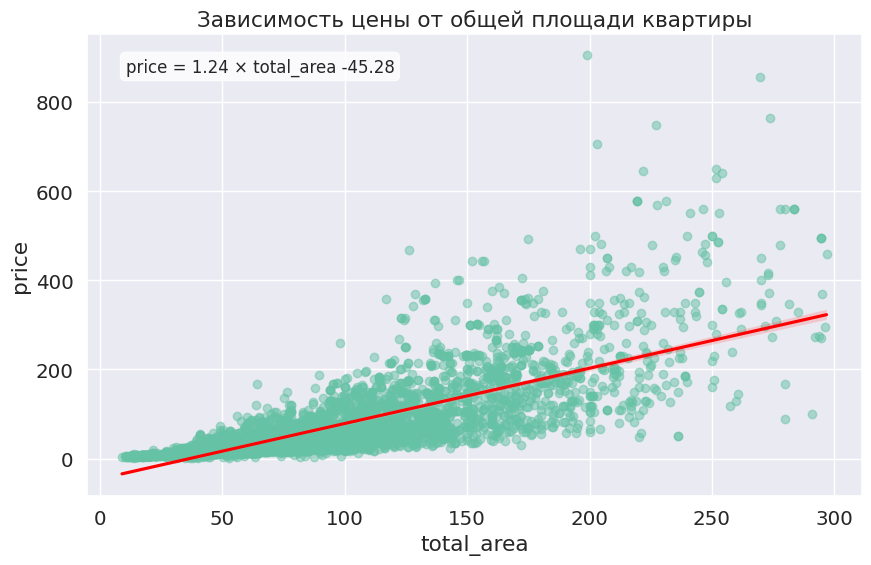

In [10]:
# Получаем параметры модели для формулы
intercept = lm_results.params["Intercept"]
slope = lm_results.params["total_area"]
formula_text = f"price = {slope:.2f} × total_area {intercept:.2f}"

plt.figure(figsize=(10, 6))
sns.regplot(
    x="total_area", y="price", data=flats, scatter_kws={"alpha": 0.5}, line_kws={"color": "red"}
)
plt.title("Зависимость цены от общей площади квартиры")

# Добавляем формулу
plt.text(
    0.05,
    0.95,
    formula_text,
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

plt.show()

Можно извлечь результаты отдельных тестов, например, проверка гипотезы о незначимости коэффициента перед признаком `total_area`

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.2</span> <span style="color:inherit;">Проверка гипотез в линейной регрессии</span>


Когда мы строим модель (OLS в нашем случае), важно понимать, какие признаки реально влияют на целевую переменную, а какие — случайный шум. Для этого используют `t-тест` коэффициента: проверяем гипотезу, что коэффициент перед признаком равен нулю. Если `t-тест` даёт  `p-value < 0.05`, значит признак значим и реально вносит вклад в модель; если `p-value > 0.05`  — эффект можно считать случайным.

Такие тесты помогают интерпретировать модель, делать её проще, наглядно показывать важность признаков в отчётах или презентациях и защищать перед начальством🤗

In [11]:
result = lm_results.t_test("total_area = 0")
result

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             1.2405      0.026     47.695      0.000       1.189       1.291

Выполнен `t-test` для проверки гипотезы `total_area = 0`. Это значит, что мы проверяем гипотезу о том, что коэффициент при total_area равен нулю (этот признак не значим)

Видим, что коэффициент существенно отличается от нуля (p < 0.001), что указывает на статистически значимый эффект.

Доверительный интервал коэффициента в линейной модели показывает, в каком диапазоне с определённой вероятностью лежит **истинное влияние признака на целевую переменную**. Например, если оценка коэффициента `c0 = 1.24` с 95%-ным интервалом `[1.19, 1.29]`, это значит, что реальное значение эффекта, которое мы бы получили при бесконечном повторении эксперимента, почти точно находится в этом диапазоне.  


Проверить можно любую гипотезу, например сравним коэффициент не с нулем, а с единицей

In [12]:
result1 = lm_results.t_test("total_area = 1")
result1

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             1.2405      0.026      9.246      0.000       1.189       1.291

In [13]:
result1 = lm_results.t_test("total_area*2 = 1")
result1

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             2.4809      0.052     28.470      0.000       2.379       2.583

Но смысл теста теряется, если он никак не связан с данными

Можно извлечь отдельные числа

In [14]:
result.pvalue

array(0.)

In [15]:
result.conf_int()

array([[1.18948496, 1.29143446]])

Посмотрим на ковариационную матрицу вектора $\widehat{\theta}$ **в условиях гомоскедастичности**, что в данном случае не выполнено.

In [16]:
lm_results.cov_params()

,Intercept,total_area
Intercept,2.983614,-0.044072
total_area,-0.044072,0.000676


Ковариационная матрица оценок коэффициентов описывает **насколько неопределённы оценки параметров** модели и **как эти неопределённости связаны между собой**.

**Что она показывает:**
- Диагональные элементы — дисперсии отдельных коэффициентов (чем они больше, тем менее точна оценка).  
- Вне диагонали — ковариации между коэффициентами (если признаки скоррелированы, ошибки в их оценках тоже связаны).  

**Зачем нужна**

Из этой матрицы считаются стандартные отклонения коэффициентов (квадратные корни из диагональных элементов).  
На их основе строятся *t*-статистики, *p*-значения и доверительные интервалы.  
Таким образом, именно она определяет статистическую достоверность модели.

*t*-статистика для коэффициента вычисляется так:
$$
t = \frac{\widehat{\theta}_j - \theta_{0,j}}{\sqrt{\widehat{\mathsf{D}}(\widehat{\theta})_{jj}}}
$$





### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.3</span> <span style="color:inherit;">Пример с несколькими признаками</span>

Рассмотрим регрессию, задаваемую формулой `price ~ total_area + living_area + min_to_metro`, указав тип используемой оценки матрицы ковариаций в предположении гетероскедастичности. Такая формула означает модель
$$price = \theta_0 + \theta_1 \cdot total\_area + \theta_2 \cdot living\_area + \theta_3 \cdot min\_to\_metro$$

<!--
*[Подробнее про синтаксис формул](https://www.statsmodels.org/stable/example_formulas.html*)

*[Можно также использовать более привычный формат](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html )(обратите внимание, сначала нужно передать таргет, а потом фичи)*
-->

Посмотрим на сводку по модели.

In [17]:
model2 = smf.ols("price ~ total_area + living_area + min_to_metro", flats)
results2 = model2.fit(cov_type="HC3")
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.585
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     377.5
Date:                Thu, 23 Oct 2025   Prob (F-statistic):          2.72e-218
Time:                        17:03:06   Log-Likelihood:                -22553.
No. Observations:                4422   AIC:                         4.511e+04
Df Residuals:                    4418   BIC:                         4.514e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -37.0759      2.280    -16.263   

OLS не умеет работать с пропущенными значениями, если просто загрузить в модель датасет с пропущенными значениями, то модель не выдаст нам ошибку, а по-тихому выкинет все строки с пропусками:

In [18]:
print(results2.nobs)  # было 6930

4422.0


Как и раньше, можно извлечь результаты отдельных тестов

In [19]:
results2.t_test("total_area = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             1.1995      0.086     13.965      0.000       1.031       1.368

Можно использовать  f-критерий для проверки нескольких линейных гипотез.

Например, проверим гипотезу об одновременной незначимости коэффициентов перед признаками `livesp`, `dist`.

In [20]:
print(results2.f_test("(living_area=0), (min_to_metro=0)"))

<F test: F=2.752554270983285, p=0.06387413545147869, df_denom=4.42e+03, df_num=2>


Можно проверить гипотезу о равенстве $\theta_{totsp} = \theta_{dist}$.

In [21]:
print(results2.f_test("(living_area=min_to_metro)"))

<F test: F=3.54717269432591, p=0.05971263215180059, df_denom=4.42e+03, df_num=1>


## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">Обобщенная линейная модель</span>


Классическая линейная регрессия (Ordinary Least Squares, OLS) моделирует зависимую переменную $y$ как линейную комбинацию признаков $x$ плюс шум:

$$
y = x^T \theta + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2)
$$

Здесь шум $\varepsilon$ предполагается **нормально распределённым** с **постоянной дисперсией** $\sigma^2$ (это называется **гомоскедастичностью**). То есть, независимо от значения предсказания $x^T \theta$, разброс ошибок всегда одинаковый. Кроме того, $y$ может принимать любые вещественные значения.
Но в реальных задачах данные часто нарушают эти предположения, поэтому мы переходим к __GLM__

**Основные компоненты GLM**

GLM расширяет линейную регрессию, моделируя не сам $y$, а его **математическое ожидание** $\mu(x)$ через **функцию связи** (link function). Это позволяет гибко работать с данными разной природы.


* Математическое ожидание $y$ (из экспоненциального семейства) зависит от признаков $x$:

    $$
    \mathsf{E}_x Y = \mu(x)
    $$

* Мы связываем $\mu(x)$ с линейной комбинацией признаков $x^T \theta$ через функцию связи $g(\cdot)$:

    $$
    g(\mu(x)) = x^T \theta
    $$

* Обратное преобразование даёт предсказание:

    $$
    \mu(x) = g^{-1}(x^T \theta)
    $$

    Функция связи $g$ "линеаризует" зависимость, чтобы учесть особенности данных. Например, для бинарных данных $g$ ограничивает $\mu$ интервалом $[0, 1]$, а для счётных — делает $\mu$ положительным.



* Модель выдаёт предсказание, преобразуя линейную комбинацию признаков через обратную функцию связи:

    $$
    \widehat{y} = g^{-1}(x^T \widehat{\theta})
    $$

    Здесь $\widehat{\theta}$ — оценки параметров, полученные в процессе обучения.

**Примеры функций связи**

Разные типы данных требуют разных распределений и функций связи. Вот основные примеры:

| Тип данных        | Распределение     | Функция связи $g(\mu)$            | Интерпретация                     |
|-------------------|-------------------|------------------------------------|-----------------------------------|
| Непрерывные       | Нормальное        | $g(\mu) = \mu$                    | Классическая линейная регрессия   |
| Бинарные          | Биномиальное      | $g(\mu) = \log\frac{\mu}{1-\mu}$ | Логистическая регрессия           |
| Счётные события    | Пуассона          | $g(\mu) = \log(\mu)$              | Пуассоновская регрессия           |




**Biopsy (Breast Cancer)**

Данные о биопсиях опухолей молочной железы были собраны в Университетской больнице Висконсина (Мэдисон) под руководством Dr. William H. Wolberg. Всего 699 наблюдений пациентов с известным исходом (доброкачественная или злокачественная опухоль). Каждый из девяти морфологических признаков оценивался врачом по шкале от 1 до 10.


| Переменная | Английский термин | Русское описание |
|------------|-----------------|----------------|
| `ID`       | Sample ID       | Идентификатор образца (неуникальный) |
| `V1`       | Clump thickness | Плотность клеточного скопления |
| `V2`       | Uniformity of cell size | Однородность размера клеток |
| `V3`       | Uniformity of cell shape | Однородность формы клеток |
| `V4`       | Marginal adhesion | Адгезия по краю клеточного скопления |
| `V5`       | Single epithelial cell size | Размер отдельных эпителиальных клеток |
| `V6`       | Bare nuclei | Наличие оголённых ядер (16 пропусков) |
| `V7`       | Bland chromatin | Равномерность распределения хроматина |
| `V8`       | Normal nucleoli | Выраженность ядрышек |
| `V9`       | Mitoses | Количество митозов |
| `class`    | Tumor class | Класс опухоли: `"benign"` (доброкачественная) или `"malignant"` (злокачественная) |



**Цель анализа**

На основе морфологических признаков оценить вероятность того, что опухоль доброкачественная. Это задача **бинарной классификации**, где зависимая переменная принимает значения:

$$
y =
\begin{cases}
1, & \text{если опухоль доброкачественная (benign)} \\
0, & \text{если злокачественная (malignant)}
\end{cases}
$$


In [22]:
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
cancer = get_rdataset("biopsy", package="MASS").data

columns = [
    "Плотность клеточного скопления",
    "Однородность размера клеток",
    "Однородность формы клеток",
    "Адгезия по краю клеточного скопления",
    "Размер отдельных эпителиальных клеток",
    "Наличие оголённых ядер",
    "Равномерность распределения хроматина",
    "Выраженность ядрышек",
    "Количество митозов",
]

cancer = cancer.set_index("ID")
cancer = cancer.dropna()
cancer.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,class
ID,,,,,,,,,,
1000025,5,1,1,1,2,1.0,3,1,1,benign
1002945,5,4,4,5,7,10.0,3,2,1,benign
1015425,3,1,1,1,2,2.0,3,1,1,benign
1016277,6,8,8,1,3,4.0,3,7,1,benign
1017023,4,1,1,3,2,1.0,3,1,1,benign


Приведем класс к числовому

In [23]:
cancer["y"] = (cancer["class"] == "benign") * 1
cancer = cancer.drop(["class"], axis=1)

cancer.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,y
count,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000
mean,4.442167,3.150805,3.215227,2.830161,3.234261,3.544656,3.445095,2.869693,1.603221,0.650073
std,2.820761,3.065145,2.988581,2.864562,2.223085,3.643857,2.449697,3.052666,1.732674,0.477296
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,0.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000,1.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.000000


Определим модель &mdash; линейную комбинацию всех признаков. Обучим GLM, используя биномиальное семейство (`sm.families.Binomial`), что соответствует логистической регрессии.

In [24]:
all_params = "+".join(cancer.columns.difference(["y"]))
glm_model = smf.glm("y ~ " + all_params, cancer, family=sm.families.Binomial())
glm_results = glm_model.fit()

Посмотрим статистические свойства обученной модели. Интерпретация таблицы аналогична таблице в простой линейной регрессии, см. выше.

In [25]:
print(glm_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  683
Model:                            GLM   Df Residuals:                      673
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -51.444
Date:                Thu, 23 Oct 2025   Deviance:                       102.89
Time:                        17:03:07   Pearson chi2:                     592.
No. Iterations:                     8   Pseudo R-squ. (CS):             0.6815
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.1039      1.175      8.600      0.0

Также можно найти odds ratios.


Коэффициенты логистической регрессии $\beta_j$ показывают изменение **логарифма отношения шансов** события $y=1$ при изменении признака на единицу.  
Чтобы получить интерпретируемые значения, коэффициенты переводят из логарифмической шкалы:

$$
\text{odds ratio} = e^{\beta_j}
$$

In [26]:
odds_ratios = np.exp(glm_results.params)
odds_ratios.index = np.concat([["Intercept"], columns])
print("\nOdds Ratios:")
print(odds_ratios)


Odds Ratios:
Intercept                                24439.164900
Плотность клеточного скопления               0.585661
Однородность размера клеток                  1.006299
Однородность формы клеток                    0.724186
Адгезия по краю клеточного скопления         0.718466
Размер отдельных эпителиальных клеток        0.907887
Наличие оголённых ядер                       0.681796
Равномерность распределения хроматина        0.639424
Выраженность ядрышек                         0.808131
Количество митозов                           0.585766
dtype: float64




**Отношение шансов (odds ratio)** показывает, во сколько раз изменяются шансы наступления события при увеличении признака на 1 единицу, при прочих равных.

* Если $ \text{odds ratio} > 1 $ — рост признака увеличивает вероятность события (в нашем случае — доброкачественной опухоли).
* Если $ \text{odds ratio} < 1 $ — рост признака уменьшает вероятность события (увеличивает риск злокачественности).
* Если $ \text{odds ratio} = 1 $ — признак не влияет на исход.



В модели для биопсий, например:

| Признак | Коэффициент | Odds Ratio | Интерпретация |
|----------|--------------|-------------|---------------|
| `V1` (clump thickness) | -0.535 | 0.59 | При увеличении плотности скопления клеток на 1 балл шансы доброкачественной опухоли уменьшаются примерно в 1.7 раза (1 / 0.59). |
| `V6` (bare nuclei) | -0.383 | 0.68 | Чем больше оголённых ядер, тем меньше вероятность доброкачественности. |
| `V4` (marginal adhesion) | -0.33 | 0.72 | Более высокая адгезия по краю связана с большей вероятностью злокачественности. |



**Замечание**

Отношения шансов — не то же самое, что вероятности.  
Например, $ \text{odds} = \frac{p}{1-p} $, и при $p=0.8$ odds = 4, а при $p=0.5$ odds = 1.  
Поэтому изменения odds ratio интерпретируются в **мультипликативных** терминах, а не в процентах вероятности напрямую.


И можно, использая ошибки модели, сделать доверительный интервал для предсказания вероятности.

В `sklearn.LogisticRegression` мы получаем только коэффициенты, но не стандартные ошибки и ковариации, а значит не можем построить доверительный интервал напрямую.

In [27]:
X_new = pd.DataFrame(
    glm_results.model.exog, columns=glm_results.model.exog_names, index=cancer.index
)

prediction_results = glm_results.get_prediction(X_new)
prediction_summary = prediction_results.summary_frame(alpha=0.05)
prediction_summary.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper
0,0.983953,0.008249,0.956565,0.994177
1,0.091191,0.068484,0.019478,0.336357
2,0.991862,0.004521,0.975999,0.997270
3,0.239065,0.179110,0.043623,0.683944
4,0.981833,0.009122,0.952007,0.993255


Таким образом, теперь каждое предсказание вероятности имеет интервал, например 0.24 (индекс 3) → [0.04, 0.68], и мы видим не только точечную оценку, но и её надежность.



Посмотрим на индивидуальные предсказания:

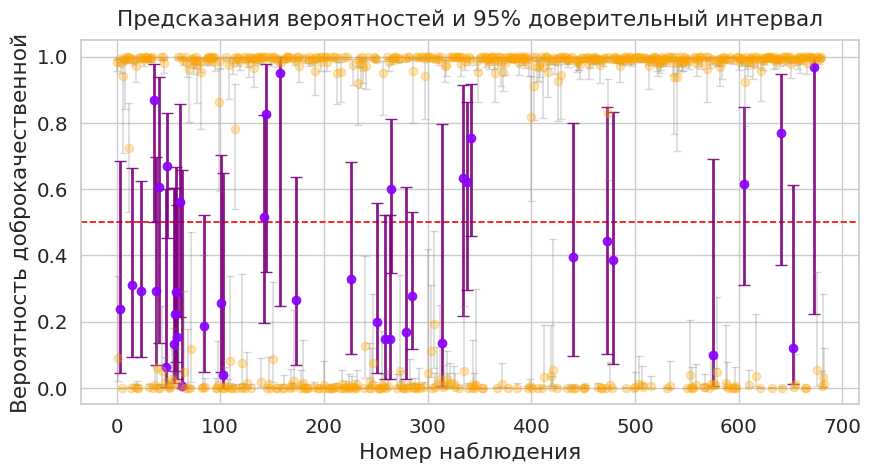

In [28]:
# вычисляем, пересекает ли доверительный интервал границу 0.5
crosses_boundary = (prediction_summary["mean_ci_lower"] <= 0.5) & (
    prediction_summary["mean_ci_upper"] >= 0.5
)
with sns.axes_style("whitegrid"):
    plt.figure(figsize=(9, 5))
    plt.axhline(0.5, color="red", linestyle="--", linewidth=1.2)

    # разбиваем на две группы
    idx_cross = np.where(crosses_boundary)[0]
    idx_no_cross = np.where(~crosses_boundary)[0]

    # интервалы, пересекающие 0.5 — яркие
    plt.errorbar(
        idx_cross,
        prediction_summary.loc[idx_cross, "mean"],
        yerr=[
            prediction_summary.loc[idx_cross, "mean"]
            - prediction_summary.loc[idx_cross, "mean_ci_lower"],
            prediction_summary.loc[idx_cross, "mean_ci_upper"]
            - prediction_summary.loc[idx_cross, "mean"],
        ],
        fmt="o",
        ecolor="purple",
        color="#8b00ff",
        elinewidth=2,
        capsize=4,
        alpha=0.9,
    )

    # интервалы, не пересекающие 0.5 — полупрозрачные
    plt.errorbar(
        idx_no_cross,
        prediction_summary.loc[idx_no_cross, "mean"],
        yerr=[
            prediction_summary.loc[idx_no_cross, "mean"]
            - prediction_summary.loc[idx_no_cross, "mean_ci_lower"],
            prediction_summary.loc[idx_no_cross, "mean_ci_upper"]
            - prediction_summary.loc[idx_no_cross, "mean"],
        ],
        fmt="o",
        ecolor="gray",
        color="orange",
        elinewidth=1.2,
        capsize=3,
        alpha=0.3,
    )

plt.ylabel("Вероятность доброкачественной")
plt.xlabel("Номер наблюдения")
plt.title("Предсказания вероятностей и 95% доверительный интервал", pad=10)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Видим, что хотя для большинства объектов модель довольно уверенно предсказывает результат, некоторым предсказаниям мы все равно не можем верить до конца и эта информация может нам в будем пригодиться.

Можем посмотреть вероятность отнесения объекта к тому или иному классу при произвольных значениях остальных признаков, __вместе с доверительным интервалом__. Один признак будем варьировать, а остальные зафиксируем на среднем:

In [29]:
def predict_glm_ci(
    x_values: Iterable[Union[int, float]], feature_name: str, glm_results: GLMResultsWrapper
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Вычисляет вероятности и 95% доверительные интервалы для диапазона значений.

    Функция варьирует значения одного признака (`feature_name`), в то время как
    остальные признаки фиксируются на их среднем значении.

    Args:
        x_values: Итерируемый объект со значениями для варьируемого признака.
        feature_name: Имя варьируемого признака (колонки в данных).
        glm_results: Результат работы модели GLM из библиотеки statsmodels.

    Returns:
        Кортеж из трех numpy-массивов: (вероятности, нижние и верхние границы ДИ).
    """
    # Берём матрицу признаков и считаем средние значения
    X_mean = pd.DataFrame(glm_results.model.exog, columns=glm_results.model.exog_names).mean()

    # Создаём датафрейм, где все признаки фиксированы на среднем, кроме варьируемого
    X_new = pd.DataFrame([X_mean.copy() for _ in x_values])
    X_new[feature_name] = x_values

    # Получаем предсказания и доверительные интервалы через statsmodels
    prediction_results = glm_results.get_prediction(X_new)
    prediction_summary = prediction_results.summary_frame(alpha=0.05)

    probs = prediction_summary["mean"].to_numpy()
    ci_lowers = prediction_summary["mean_ci_lower"].to_numpy()
    ci_uppers = prediction_summary["mean_ci_upper"].to_numpy()

    return probs, ci_lowers, ci_uppers

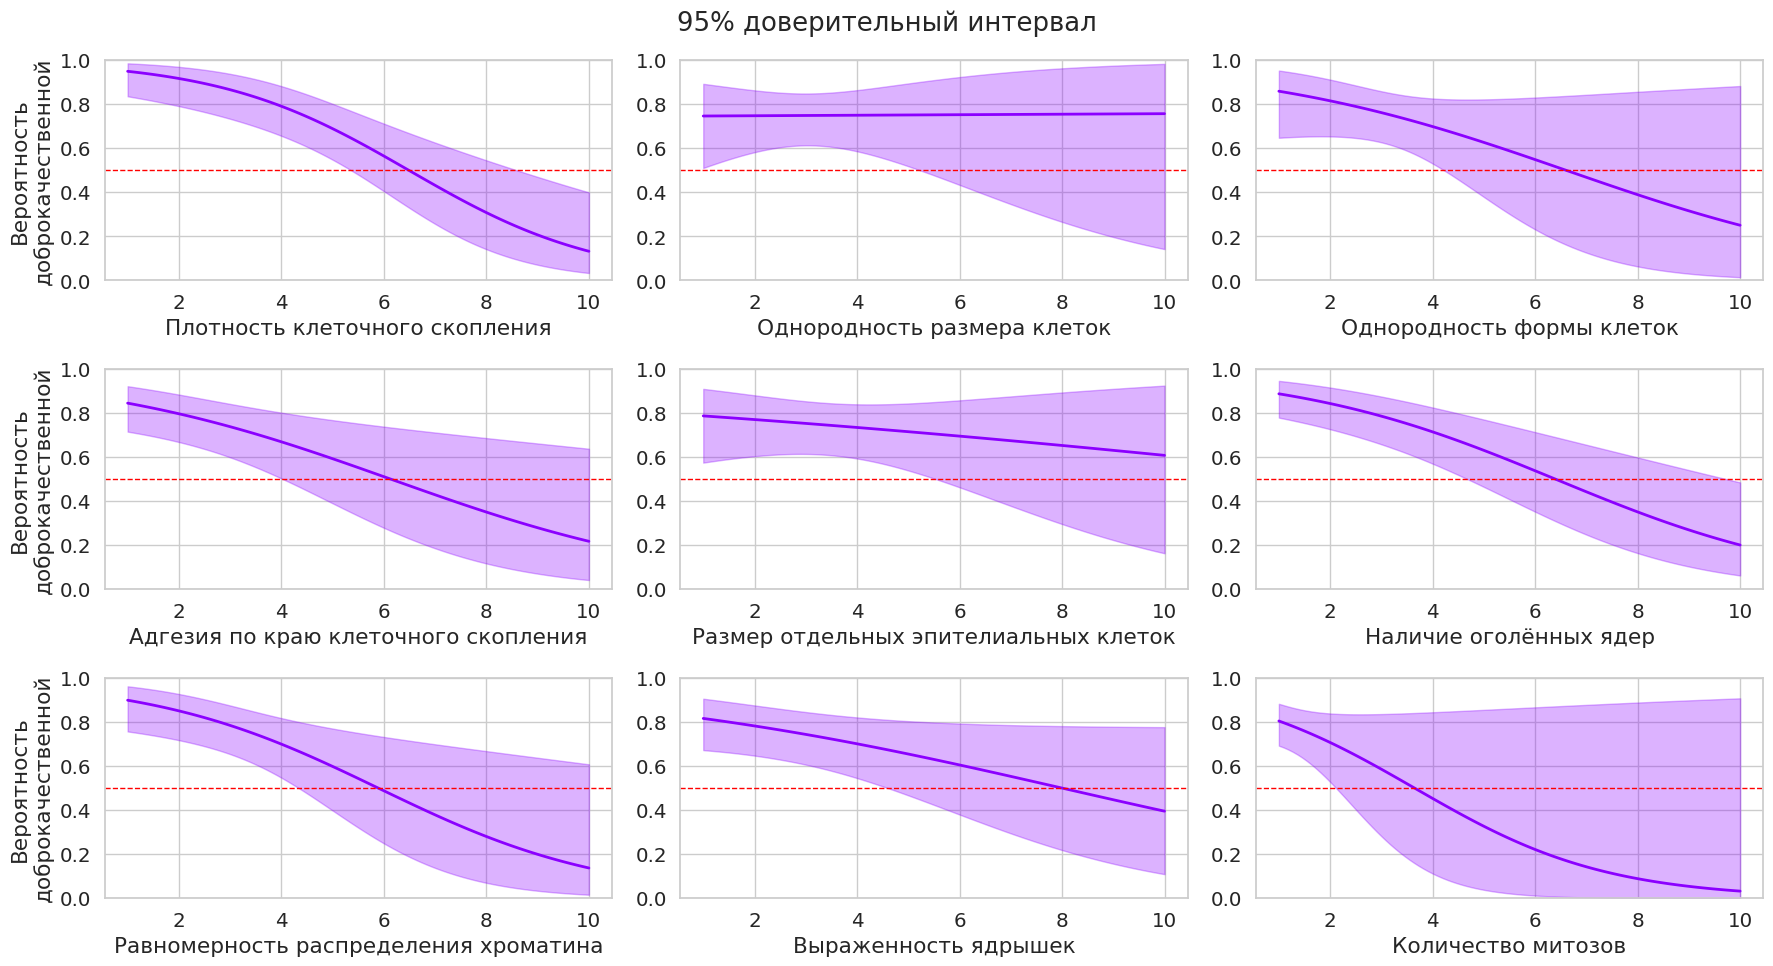

In [30]:
sns.set_style("whitegrid")

X = pd.DataFrame(glm_results.model.exog, columns=glm_results.model.exog_names)
feature_names = [name for name in X.columns if name != "Intercept"]
base_point = X.mean().to_dict()  # средние значения признаков

n_features = len(feature_names)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(feature_names):
    ax = axes[i]
    x_range = np.linspace(X[feature].min(), X[feature].max(), 100)
    probs, ci_lower, ci_upper = predict_glm_ci(x_range, feature, glm_results)

    ax.plot(x_range, probs, color="#8b00ff", lw=2, label="Predicted Probability")
    ax.fill_between(x_range, ci_lower, ci_upper, color="#8b00ff", alpha=0.3)
    ax.axhline(0.5, color="red", linestyle="--", lw=1)
    ax.set_xlabel(columns[i])
    if i % n_cols == 0:
        ax.set_ylabel("Вероятность\nдоброкачественной")
    ax.set_ylim(0, 1)

fig.suptitle("95% доверительный интервал", y=0.97)
plt.tight_layout()
plt.show()

Использование доверительных интервалов для предсказанных вероятностей позволило оценить неопределённость прогнозов. Мы увидели, что для некоторых наблюдений интервалы пересекают границу 0.5, что указывает на неуверенность модели в классификации, что важно учитывать при принятии решений. Это подчёркивает необходимость интерпретации не только точечных оценок, но и их погрешностей.

GLM стоит применять, когда данные имеют нестандартное распределение или гетероскедастичность, а также когда важна интерпретация результатов.
В работе эта модель может приготиться для использования на данных которые распределены, например по Пуассону - количество кликов, покупок, заходов на сайт.

В нашем случае, с использование GLM мы смогли построить более точные доверительные интервалы для вероятности отношения к классу для предсказаний, так как эта модель также моделирует дисперсию через линк-функцию и возвращает ковариационную матрицу коэффициентов.

Все эти возможности помогут __интерпретировать__ результаты правильно и __доверять__ модели, или хотя бы __знать__, где доверять.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>